# Olympics Data

## Introduction

## Required Packages

In [6]:
try:
    import pandas as pd
except ImportError:
    import pip
    pip.main(['install', 'pandas'])
    import pandas as pd

try:
    import matplotlib.pyplot as plt
except ImportError:
    import pip
    pip.main(['install', 'matplotlib'])
    import matplotlib.pyplot as plt

try:
    import seaborn as sns
except ImportError:
    import pip
    pip.main(['install', 'seaborn'])
    import seaborn as sns

## Data Preparation

In [12]:
olympics = pd.read_csv("olympics.csv")
olympics.head()

,id,name,sex,age,height,weight,team,noc,games,year,season,city,sport,event,medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


In [10]:
olympics.describe(include = 'all')

,id,name,sex,age,height,weight,team,noc,games,year,season,city,sport,event,medal
count,271116.000000,271116,271116,261642.000000,210945.000000,208241.000000,271116,271116,271116,271116.000000,271116,271116,271116,271116,39783
unique,NaN,134731,2,NaN,NaN,NaN,1184,230,51,NaN,2,42,66,765,3
top,NaN,Robert Tait McKenzie,M,NaN,NaN,NaN,United States,USA,2000 Summer,NaN,Summer,London,Athletics,Football Men's Football,Gold
freq,NaN,58,196594,NaN,NaN,NaN,17847,18853,13821,NaN,222552,22426,38624,5733,13372
mean,68248.954396,NaN,NaN,25.556898,175.338970,70.702393,NaN,NaN,NaN,1978.378480,NaN,NaN,NaN,NaN,NaN
std,39022.286345,NaN,NaN,6.393561,10.518462,14.348020,NaN,NaN,NaN,29.877632,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,10.000000,127.000000,25.000000,NaN,NaN,NaN,1896.000000,NaN,NaN,NaN,NaN,NaN
25%,34643.000000,NaN,NaN,21.000000,168.000000,60.000000,NaN,NaN,NaN,1960.000000,NaN,NaN,NaN,NaN,NaN
50%,68205.000000,NaN,NaN,24.000000,175.000000,70.000000,NaN,NaN,NaN,1988.000000,NaN,NaN,NaN,NaN,NaN
75%,102097.250000,NaN,NaN,28.000000,183.000000,79.000000,NaN,NaN,NaN,2002.000000,NaN,NaN,NaN,NaN,NaN


In [14]:
# Number of missing values for each variable and its corresponding percentage

missing_values = olympics.isna().sum()
missing_olympics = (olympics.isna().sum() / len(olympics)) * 100
missing_table = pd.DataFrame({'Missing Values': missing_values,
                                   'Percentage Missing': missing_olympics})
missing_table.sort_values(by='Missing Values', ascending=False, inplace=True)
print(missing_table)

        Missing Values  Percentage Missing
medal           231333           85.326207
weight           62875           23.191180
height           60171           22.193821
age               9474            3.494445
id                   0            0.000000
name                 0            0.000000
sex                  0            0.000000
team                 0            0.000000
noc                  0            0.000000
games                0            0.000000
year                 0            0.000000
season               0            0.000000
city                 0            0.000000
sport                0            0.000000
event                0            0.000000


In [16]:
olympics.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271116 entries, 0 to 271115
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   id      271116 non-null  int64  
 1   name    271116 non-null  object 
 2   sex     271116 non-null  object 
 3   age     261642 non-null  float64
 4   height  210945 non-null  float64
 5   weight  208241 non-null  float64
 6   team    271116 non-null  object 
 7   noc     271116 non-null  object 
 8   games   271116 non-null  object 
 9   year    271116 non-null  int64  
 10  season  271116 non-null  object 
 11  city    271116 non-null  object 
 12  sport   271116 non-null  object 
 13  event   271116 non-null  object 
 14  medal   39783 non-null   object 
dtypes: float64(3), int64(2), object(10)
memory usage: 31.0+ MB


In [18]:
olympics['sex'].unique()

array(['M', 'F'], dtype=object)

In [20]:
olympics['season'].unique()

array(['Summer', 'Winter'], dtype=object)

In [22]:
olympics['medal'].unique()

array([nan, 'Gold', 'Bronze', 'Silver'], dtype=object)

In [24]:
olympics['sport'].unique()

array(['Basketball', 'Judo', 'Football', 'Tug-Of-War', 'Speed Skating',
       'Cross Country Skiing', 'Athletics', 'Ice Hockey', 'Swimming',
       'Badminton', 'Sailing', 'Biathlon', 'Gymnastics',
       'Art Competitions', 'Alpine Skiing', 'Handball', 'Weightlifting',
       'Wrestling', 'Luge', 'Water Polo', 'Hockey', 'Rowing', 'Bobsleigh',
       'Fencing', 'Equestrianism', 'Shooting', 'Boxing', 'Taekwondo',
       'Cycling', 'Diving', 'Canoeing', 'Tennis', 'Modern Pentathlon',
       'Figure Skating', 'Golf', 'Softball', 'Archery', 'Volleyball',
       'Synchronized Swimming', 'Table Tennis', 'Nordic Combined',
       'Baseball', 'Rhythmic Gymnastics', 'Freestyle Skiing',
       'Rugby Sevens', 'Trampolining', 'Beach Volleyball', 'Triathlon',
       'Ski Jumping', 'Curling', 'Snowboarding', 'Rugby',
       'Short Track Speed Skating', 'Skeleton', 'Lacrosse', 'Polo',
       'Cricket', 'Racquets', 'Motorboating', 'Military Ski Patrol',
       'Croquet', 'Jeu De Paume', 'Roque', 'Al

In [26]:
#Dropping NA values
olympics_cleaned = olympics.dropna()
olympics_cleaned.head()

,id,name,sex,age,height,weight,team,noc,games,year,season,city,sport,event,medal
40,16,Juhamatti Tapio Aaltonen,M,28.0,184.0,85.0,Finland,FIN,2014 Winter,2014,Winter,Sochi,Ice Hockey,Ice Hockey Men's Ice Hockey,Bronze
41,17,Paavo Johannes Aaltonen,M,28.0,175.0,64.0,Finland,FIN,1948 Summer,1948,Summer,London,Gymnastics,Gymnastics Men's Individual All-Around,Bronze
42,17,Paavo Johannes Aaltonen,M,28.0,175.0,64.0,Finland,FIN,1948 Summer,1948,Summer,London,Gymnastics,Gymnastics Men's Team All-Around,Gold
44,17,Paavo Johannes Aaltonen,M,28.0,175.0,64.0,Finland,FIN,1948 Summer,1948,Summer,London,Gymnastics,Gymnastics Men's Horse Vault,Gold
48,17,Paavo Johannes Aaltonen,M,28.0,175.0,64.0,Finland,FIN,1948 Summer,1948,Summer,London,Gymnastics,Gymnastics Men's Pommelled Horse,Gold


In [28]:
olympics_cleaned.isna().sum()

id        0
name      0
sex       0
age       0
height    0
weight    0
team      0
noc       0
games     0
year      0
season    0
city      0
sport     0
event     0
medal     0
dtype: int64

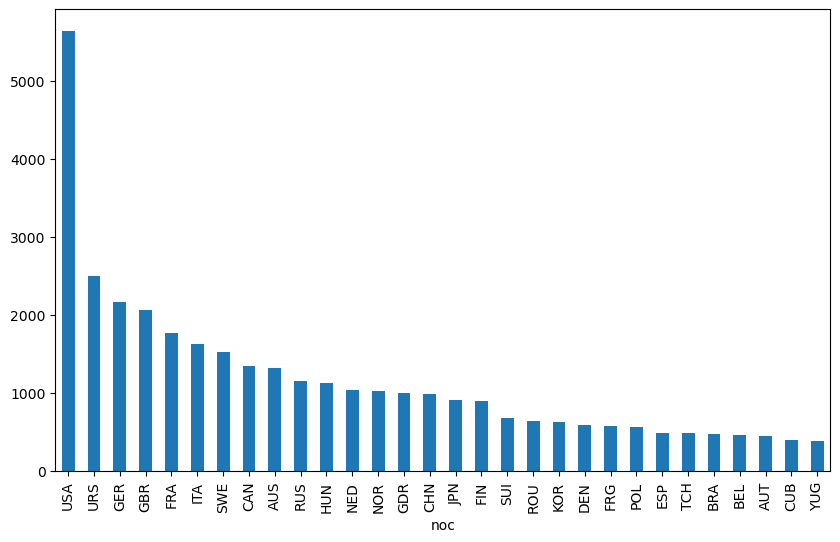

In [41]:
# 1) How has the number of medals won by different countries changed over time? What trends can be observed?
medalists = olympics[olympics['medal'].notna()]
medals = medalists.groupby(by='noc')['medal'].count().reset_index()
medals = medals.sort_values(by='medal', ascending=False)
medals.set_index('noc')['medal'].head(n=30).plot(kind='bar', figsize=(10, 6), rot=90)
plt.show()

In [ ]:
# 2) What is the gender proportion among atheltes, and how does it vary across sports and over time? Any trends?

In [30]:
#Number of females and males across the year
gender_over_time = olympics.groupby(['year', 'sex']).size().reset_index(name='Count')
gender_over_time.head()

,year,sex,Count
0,1896,M,380
1,1900,F,33
2,1900,M,1903
3,1904,F,16
4,1904,M,1285


In [32]:
#Total number of participants across the year
gender_over_time_total = gender_over_time.groupby('year')['Count'].transform('sum')
gender_over_time_total.head()

0     380
1    1936
2    1936
3    1301
4    1301
Name: Count, dtype: int64

In [45]:
#Proportion of female and male participants across the year
gender_over_time['Proportion'] = gender_over_time['Count'] / gender_over_time_total
gender_over_time.head()

,year,sex,Count,Proportion
0,1896,M,380,1.000000
1,1900,F,33,0.017045
2,1900,M,1903,0.982955
3,1904,F,16,0.012298
4,1904,M,1285,0.987702


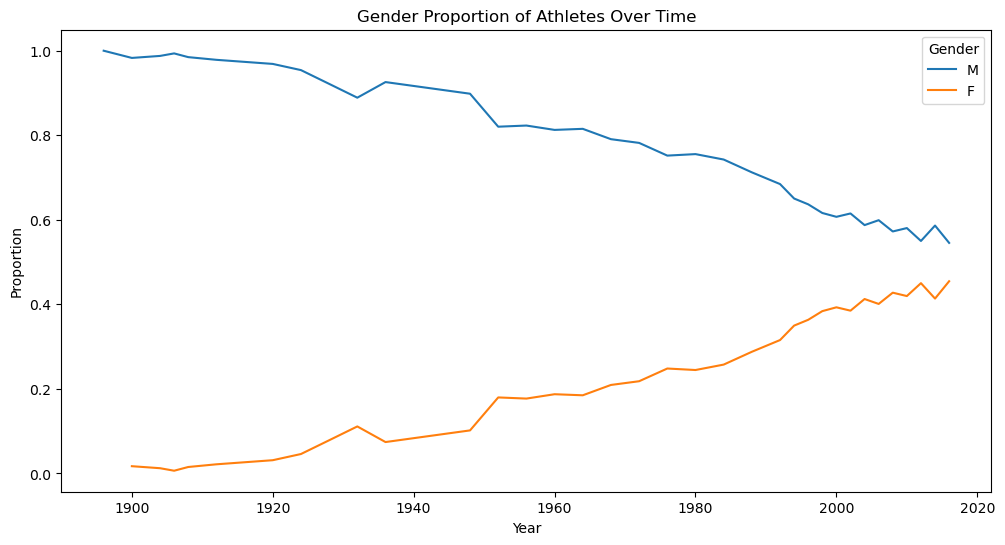

In [47]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=gender_over_time, x='year', y='Proportion', hue='sex')
plt.title('Gender Proportion of Athletes Over Time')
plt.ylabel('Proportion')
plt.xlabel('Year')
plt.legend(title='Gender')
plt.show()

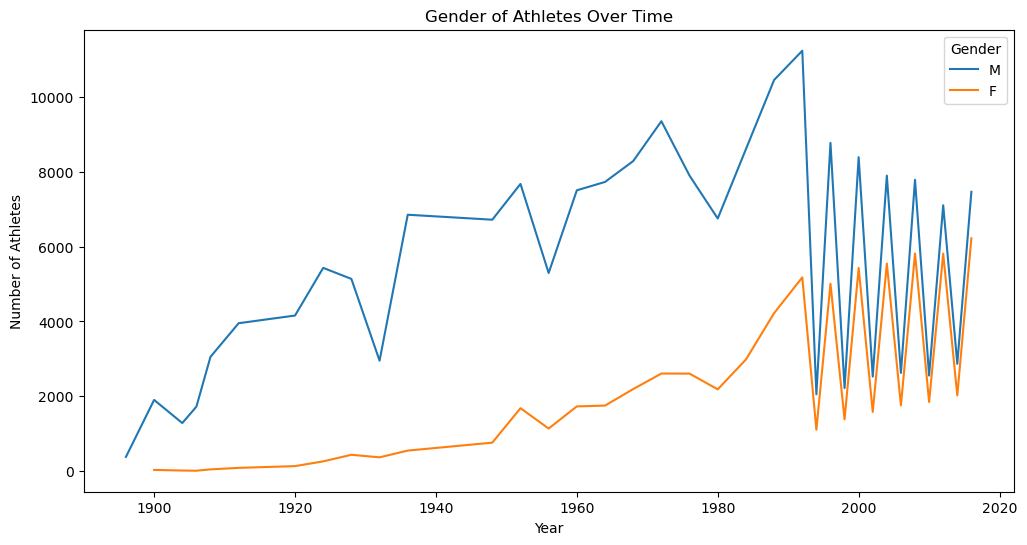

In [73]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=gender_over_time, x='year', y='Count', hue='sex')
plt.title('Gender of Athletes Over Time')
plt.ylabel('Number of Athletes')
plt.xlabel('Year')
plt.legend(title='Gender')
plt.show()

In [54]:
# 3) How is the number of athletes distributed across different sports?

In [36]:
olympics['name'].unique()
olympics['sport'].unique()

array(['Basketball', 'Judo', 'Football', 'Tug-Of-War', 'Speed Skating',
       'Cross Country Skiing', 'Athletics', 'Ice Hockey', 'Swimming',
       'Badminton', 'Sailing', 'Biathlon', 'Gymnastics',
       'Art Competitions', 'Alpine Skiing', 'Handball', 'Weightlifting',
       'Wrestling', 'Luge', 'Water Polo', 'Hockey', 'Rowing', 'Bobsleigh',
       'Fencing', 'Equestrianism', 'Shooting', 'Boxing', 'Taekwondo',
       'Cycling', 'Diving', 'Canoeing', 'Tennis', 'Modern Pentathlon',
       'Figure Skating', 'Golf', 'Softball', 'Archery', 'Volleyball',
       'Synchronized Swimming', 'Table Tennis', 'Nordic Combined',
       'Baseball', 'Rhythmic Gymnastics', 'Freestyle Skiing',
       'Rugby Sevens', 'Trampolining', 'Beach Volleyball', 'Triathlon',
       'Ski Jumping', 'Curling', 'Snowboarding', 'Rugby',
       'Short Track Speed Skating', 'Skeleton', 'Lacrosse', 'Polo',
       'Cricket', 'Racquets', 'Motorboating', 'Military Ski Patrol',
       'Croquet', 'Jeu De Paume', 'Roque', 'Al

<Axes: title={'center': 'Number of Athletes in Different Sports'}, xlabel='Sport', ylabel='Number of Athletes'>

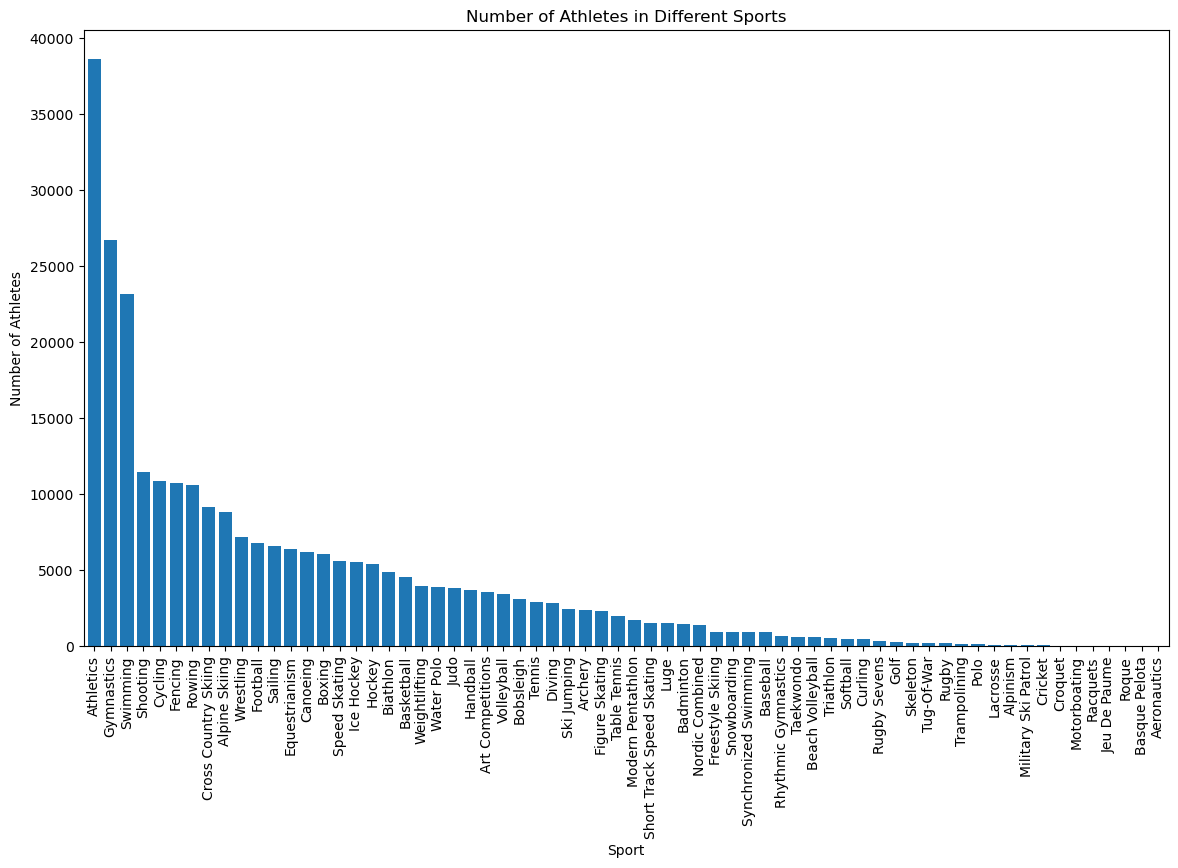

In [90]:
#filtered the data
sports_data = olympics[olympics['name'].notna() & olympics['sport'].notna()]
# groupby sport and athletes
athlete_counts = sports_data.groupby('sport')['name'].count().reset_index()
# number of athletes
athlete_counts = athlete_counts.sort_values(by='name', ascending=False)
#plot
athlete_counts.plot(kind='bar', x='sport', y='name', figsize=(14, 8), width=0.8, rot=90,
                    title='Number of Athletes in Different Sports',
                    xlabel='Sport', ylabel='Number of Athletes', legend=False)


In [40]:
# number of sports 
sports_data = olympics[olympics['name'].notna() & olympics['sport'].notna()]
number_of_sports = sports_data['sport'].nunique()
print(number_of_sports)

66


In [81]:
olympics['sport'].value_counts()

sport
Athletics        38624
Gymnastics       26707
Swimming         23195
Shooting         11448
Cycling          10859
                 ...  
Racquets            12
Jeu De Paume        11
Roque                4
Basque Pelota        2
Aeronautics          1
Name: count, Length: 66, dtype: int64

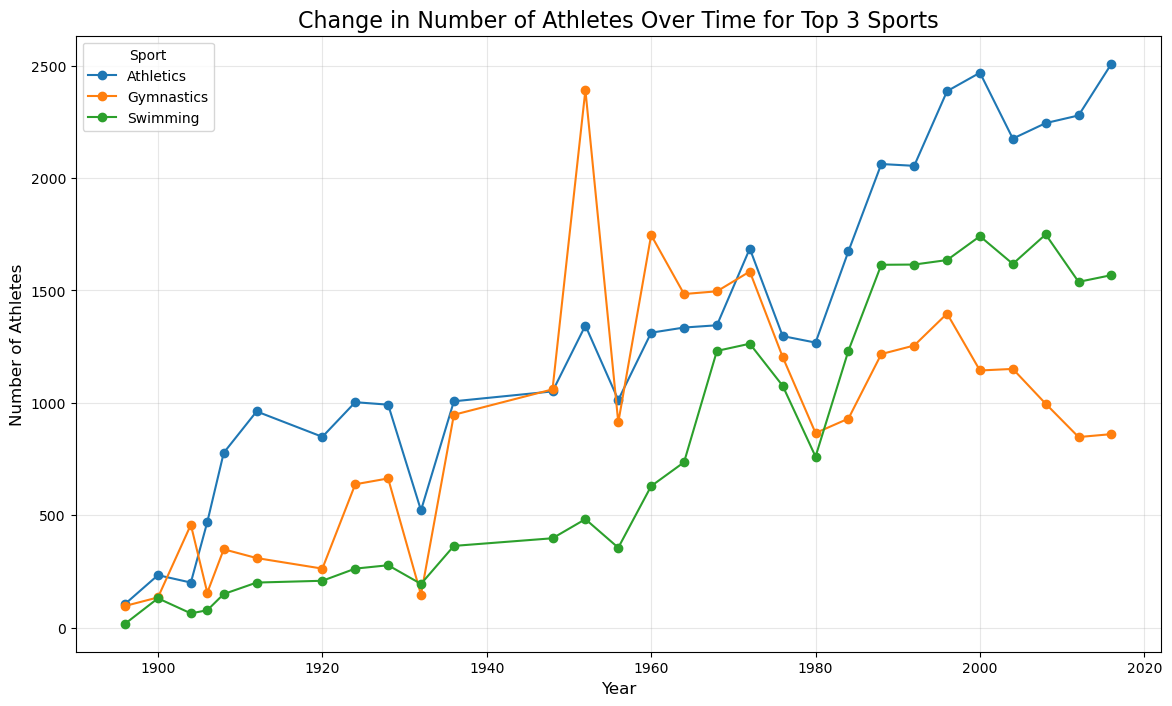

In [92]:
#top three sports
top_sports = sports_data.groupby('sport')['name'].count().nlargest(3).index
top_sports_data = sports_data[sports_data['sport'].isin(top_sports)]
#grouped by year and sport 
athletes_over_time = top_sports_data.groupby(['year', 'sport'])['name'].count().reset_index()

# created a plot
plt.figure(figsize=(14, 8))

for sport in top_sports:
    sport_data = athletes_over_time[athletes_over_time['sport'] == sport]
    plt.plot(sport_data['year'], sport_data['name'], marker='o', label=sport)

plt.title('Change in Number of Athletes Over Time for Top 3 Sports', fontsize=16)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Athletes', fontsize=12)
plt.legend(title='Sport', fontsize=10)
plt.grid(alpha=0.3)
plt.show()


In [ ]:
We began by identifying the top three sports with the highest number of participants and grouped the data.
Next, we organized the data by year and sport to create a graph illustrating the changes in athlete
participation for these top three sports over time.

In [1]:
# 4) What is the optimal age for success in various sports, and how does this vary across different athletic disciplines?

In [79]:
age_cleaned = olympics.dropna(subset=['age'])
olympics['age'] = olympics.groupby('sport')['age'].transform(lambda x: x.fillna(x.mean()))
medalists_age = age_cleaned.dropna(subset=['medal'])

In [81]:
#Check the first few rows of the cleaned data
medalists_age.head()

,id,name,sex,age,height,weight,team,noc,games,year,season,city,sport,event,medal
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
37,15,Arvo Ossian Aaltonen,M,30.0,NaN,NaN,Finland,FIN,1920 Summer,1920,Summer,Antwerpen,Swimming,Swimming Men's 200 metres Breaststroke,Bronze
38,15,Arvo Ossian Aaltonen,M,30.0,NaN,NaN,Finland,FIN,1920 Summer,1920,Summer,Antwerpen,Swimming,Swimming Men's 400 metres Breaststroke,Bronze
40,16,Juhamatti Tapio Aaltonen,M,28.0,184.0,85.0,Finland,FIN,2014 Winter,2014,Winter,Sochi,Ice Hockey,Ice Hockey Men's Ice Hockey,Bronze
41,17,Paavo Johannes Aaltonen,M,28.0,175.0,64.0,Finland,FIN,1948 Summer,1948,Summer,London,Gymnastics,Gymnastics Men's Individual All-Around,Bronze


In [83]:
# Filter for athletes who won medals
medalists_age = olympics[olympics['medal'].notna()]

In [85]:
#Group by sport and calculate the average age of medalists, rounded to two decimal places
avg_age_per_sport = medalists_age.groupby('sport')['age'].mean().round(2).reset_index()

In [87]:
#Sort by average age
avg_age_per_sport = avg_age_per_sport.sort_values(by='age', ascending=False)

In [89]:
#Results
print(avg_age_per_sport)

                        sport    age
42                      Roque  53.33
4            Art Competitions  42.42
2                    Alpinism  38.81
21              Equestrianism  35.36
39                       Polo  34.61
..                        ...    ...
13                     Boxing  23.06
48  Short Track Speed Skating  22.43
20                     Diving  22.27
54                   Swimming  20.92
41        Rhythmic Gymnastics  18.93

[66 rows x 2 columns]


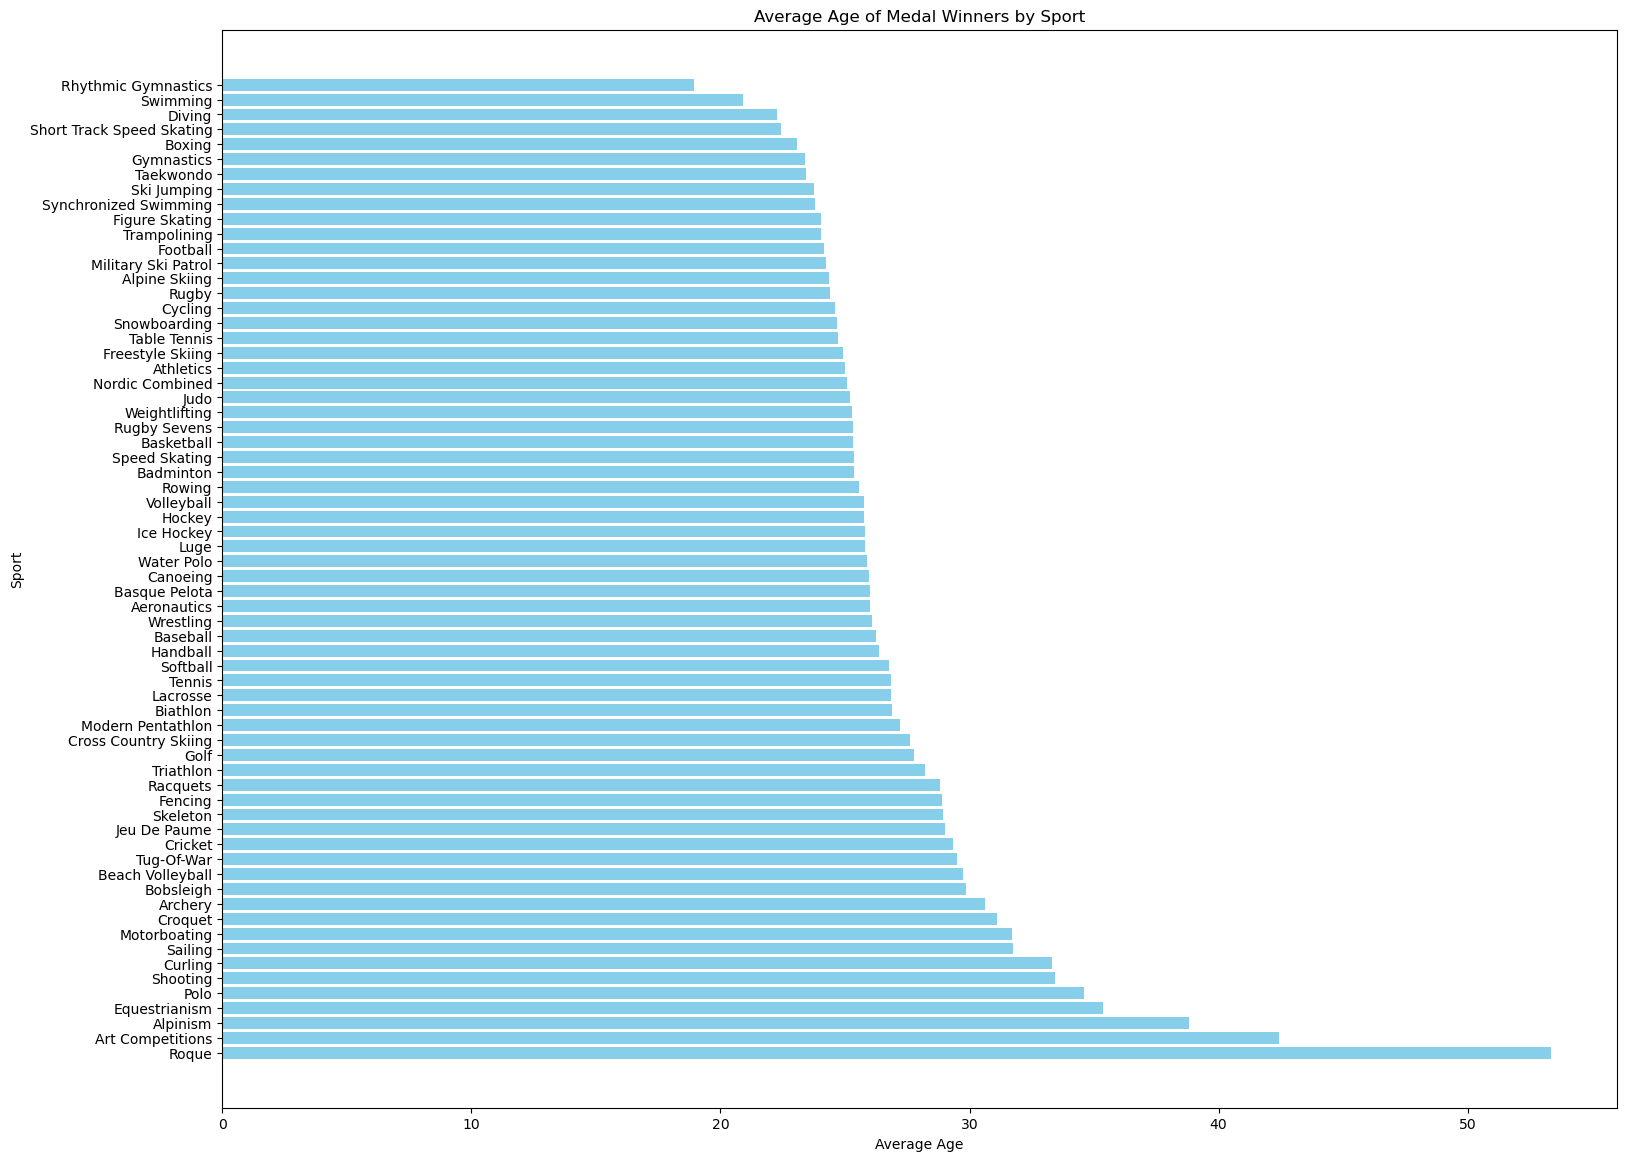

In [91]:
plt.figure(figsize=(18,14))
plt.barh(avg_age_per_sport['sport'], avg_age_per_sport['age'], color='skyblue')
plt.xlabel('Average Age')
plt.ylabel('Sport')
plt.title('Average Age of Medal Winners by Sport')
plt.show()